## 4. Persiapan lingkungan dan data

In [1]:
import sys
import re
import math
import time
import secrets
from collections import Counter
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt

BENIH_ACAK = 2026
rng = np.random.default_rng(BENIH_ACAK)
np.set_printoptions(precision=4, suppress=True)

print("Versi Python:", sys.version.split()[0])
print("Versi NumPy:", np.__version__)
print("Benih acak:", BENIH_ACAK)

Versi Python: 3.13.16
Versi NumPy: 2.1.3
Benih acak: 2026


### 4.1. Memuat email `spam.txt` dan `ham.txt`

Sumber data asli tersedia pada repositori resmi pendamping buku:

- `https://github.com/iamtrask/Grokking-Deep-Learning`
- `spam.txt` dan `ham.txt` berupa kumpulan baris token email.

Notebook mencoba mengambil file sumbernya langsung. Untuk menghemat waktu latihan, digunakan batas contoh per kelas. Jika unduhan tidak tersedia, dipakai contoh buatan yang **secara eksplisit diberi status sintetis**. Bentuk ini membuat notebook dapat dijalankan tanpa koneksi internet dan tetap memperlihatkan algoritmenya.

In [2]:
ALAMAT_DATA = "https://raw.githubusercontent.com/iamtrask/Grokking-Deep-Learning/master/"
BATAS_PER_KELAS = 700

def bersihkan_teks(teks):
    return re.findall(r"[a-z0-9<>']+", teks.lower())

def unduh_baris(nama_file):
    with urlopen(ALAMAT_DATA + nama_file, timeout=7) as respons:
        data = respons.read().decode("utf-8", errors="ignore")
    return [line.strip() for line in data.splitlines() if line.strip()]

def buat_data_sintetis(jumlah=700):
    # Contoh sepenuhnya buatan untuk mencoba alur saat file resmi tidak dapat diakses.
    subjek = ["kelas", "rapat", "laporan", "proyek", "jadwal", "dokumen", "kantor"]
    nama = ["rina", "budi", "maya", "adi", "nana", "toni"]
    umum = ["hari", "ini", "besok", "silakan", "sudah", "untuk", "bersama"]
    kata_spam = ["hadiah", "gratis", "bonus", "promo", "klaim", "diskon", "undian", "menang"]
    kata_ham = ["agenda", "pertemuan", "diskusi", "tugas", "revisi", "notulen", "kelas", "undangan"]
    spam_buatan, ham_buatan = [], []
    for _ in range(jumlah):
        a = rng.choice(kata_spam, size=3, replace=False).tolist()
        b = rng.choice(kata_ham, size=3, replace=False).tolist()
        noise = rng.choice(umum, size=3, replace=True).tolist()
        spam_buatan.append(" ".join(a + noise + [str(rng.integers(1, 10000)), rng.choice(nama)]))
        ham_buatan.append(" ".join(b + noise + [rng.choice(subjek), str(rng.integers(1, 10000))]))
    return spam_buatan, ham_buatan

try:
    spam_mentah = unduh_baris("spam.txt")[:BATAS_PER_KELAS]
    ham_mentah = unduh_baris("ham.txt")[:BATAS_PER_KELAS]
    if min(len(spam_mentah), len(ham_mentah)) < 40:
        raise ValueError("Terlalu sedikit contoh yang diunduh.")
    STATUS_DATA = "DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku"
except Exception as kesalahan:
    spam_mentah, ham_mentah = buat_data_sintetis(BATAS_PER_KELAS)
    STATUS_DATA = "DATA SINTETIS: email contoh buatan untuk demonstrasi, bukan Enron"
    print("Unduhan tidak tersedia; digunakan data sintetis.")
    print("Penyebab:", type(kesalahan).__name__)

print("STATUS:", STATUS_DATA)
print("Jumlah spam:", len(spam_mentah), "| jumlah bukan spam:", len(ham_mentah))
print("Contoh spam (awal dipotong):", spam_mentah[0][:95])
print("Contoh bukan spam (awal dipotong):", ham_mentah[0][:95])

STATUS: DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku
Jumlah spam: 700 | jumlah bukan spam: 700
Contoh spam (awal dipotong): Subject: dobmeos with hgh my energy level has gone up ! stukm introducing doctor - formulated h
Contoh bukan spam (awal dipotong): Subject: christmas tree farm pictures


### 4.2. Pembagian data dan pencegahan kebocoran yang tidak disengaja

Kita mencampur contoh masing-masing kelas menggunakan benih acak tetap, lalu memisahkan data pelatihan dan pengujian. **Kamus kata hanya dibentuk dari data pelatihan.** Dengan demikian, data pengujian tidak dipakai untuk membangun representasi atau menentukan parameter saat pelatihan.

Untuk meniru contoh embedding pada buku, tiap email diubah menjadi indeks **kata unik**. Kata yang tidak ada pada kamus diabaikan pada model demonstrasi ini; model yang lebih lengkap dapat memakai token `<unk>` dengan penanganan khusus.

In [3]:
def pisahkan_per_kelas(spam_raw, ham_raw, fraksi_latih=0.8):
    pasangan_latih, pasangan_uji = [], []
    for teks_kelas, label in [(spam_raw, 1), (ham_raw, 0)]:
        posisi = rng.permutation(len(teks_kelas))
        potong = int(len(posisi) * fraksi_latih)
        pasangan_latih += [(teks_kelas[i], label) for i in posisi[:potong]]
        pasangan_uji += [(teks_kelas[i], label) for i in posisi[potong:]]
    rng.shuffle(pasangan_latih)
    rng.shuffle(pasangan_uji)
    return pasangan_latih, pasangan_uji

latih_raw, uji_raw = pisahkan_per_kelas(spam_mentah, ham_mentah)
KATA_MAKS = 1500  # menjaga demonstrasi tetap ringan
frekuensi = Counter(kata for teks, _ in latih_raw for kata in set(bersihkan_teks(teks)))
kamus = [kata for kata, _ in frekuensi.most_common(KATA_MAKS)]
kata_ke_indeks = {kata: i for i, kata in enumerate(kamus)}

def indeks_email(teks, peta=kata_ke_indeks):
    return np.array(sorted({peta[k] for k in bersihkan_teks(teks) if k in peta}), dtype=np.int32)

x_latih = [indeks_email(teks) for teks, _ in latih_raw]
y_latih = np.array([label for _, label in latih_raw], dtype=np.int32)
x_uji = [indeks_email(teks) for teks, _ in uji_raw]
y_uji = np.array([label for _, label in uji_raw], dtype=np.int32)

print("Data latih:", len(x_latih), "| data uji:", len(x_uji))
print("Ukuran kamus:", len(kamus))
print("Rata-rata kata unik per pesan latih:", round(np.mean([len(x) for x in x_latih]), 1))
print("Contoh 12 kata umum:", kamus[:12])
assert len(x_latih) == len(y_latih) and len(x_uji) == len(y_uji)
assert all((len(x) == len(np.unique(x))) for x in x_latih)

Data latih: 1120 | data uji: 280
Ukuran kamus: 1500
Rata-rata kata unik per pesan latih: 63.2
Contoh 12 kata umum: ['subject', 'to', 'the', 'for', 'and', 'you', 'a', 'on', 'of', 'is', 'this', "'"]


## 5. Reproduksi model pendeteksi spam terpusat

Bab 15 menggunakan `Embedding(dim=1)`, penjumlahan representasi kata, fungsi sigmoid, serta kerugian kuadrat. Kita membuat komponen yang sama secara transparan dengan NumPy. Berbeda dari pemanggilan kelas `Tensor` pada Bab 13, implementasi khusus ini menghitung turunan langsung supaya notebook berdiri sendiri dan mudah diperiksa.

Untuk satu mini-batch, pembaruan parameter mengikuti \(w \leftarrow w-\alpha\nabla_w\mathcal L\). Dengan penyimpanan indeks kata, kita hanya menjumlahkan gradien untuk kata-kata yang memang ditemukan pada pesan yang sedang dilatih.

In [4]:
class ModelEmail:
    def __init__(self, ukuran_kamus):
        self.bobot = np.zeros(int(ukuran_kamus), dtype=np.float64)

    def salin(self):
        baru = ModelEmail(len(self.bobot))
        baru.bobot = self.bobot.copy()
        return baru

    def prediksi_probabilitas(self, kumpulan_indeks):
        logit = np.array([self.bobot[x].sum() for x in kumpulan_indeks], dtype=float)
        logit = np.clip(logit, -35, 35)   # menghindari luapan pada eksponensial
        return 1.0 / (1.0 + np.exp(-logit))

    def langkah_latih(self, kumpulan_indeks, label, laju_belajar=0.5):
        probabilitas = self.prediksi_probabilitas(kumpulan_indeks)
        kesalahan = float(np.mean((probabilitas - label) ** 2))
        delta = (2 * (probabilitas - label) * probabilitas * (1 - probabilitas)) / len(label)
        gradien = np.zeros_like(self.bobot)
        for email, kontribusi in zip(kumpulan_indeks, delta):
            np.add.at(gradien, email, kontribusi)
        self.bobot -= laju_belajar * gradien
        return kesalahan

def metrik(model, x, y):
    probabilitas = model.prediksi_probabilitas(x)
    pred = (probabilitas >= 0.5).astype(int)
    tp = int(np.sum((pred == 1) & (y == 1)))
    tn = int(np.sum((pred == 0) & (y == 0)))
    fp = int(np.sum((pred == 1) & (y == 0)))
    fn = int(np.sum((pred == 0) & (y == 1)))
    akurasi = (tp + tn) / max(len(y), 1)
    presisi = tp / max(tp + fp, 1)
    sensitivitas = tp / max(tp + fn, 1)
    f1 = 2 * presisi * sensitivitas / max(presisi + sensitivitas, 1e-12)
    rugi = float(np.mean((probabilitas - y) ** 2))
    return {"akurasi": akurasi, "presisi": presisi, "recall": sensitivitas,
            "f1": f1, "mse": rugi, "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def jalankan_lokal(model, x, y, epoch=1, ukuran_batch=64, alpha=0.5, generator=None):
    generator = generator if generator is not None else rng
    salinan = model.salin()
    daftar_rugi = []
    for _ in range(epoch):
        posisi = generator.permutation(len(x))
        rugi_epoch = []
        for awal in range(0, len(x), ukuran_batch):
            idx = posisi[awal:awal + ukuran_batch]
            xb = [x[int(i)] for i in idx]
            yb = y[idx]
            rugi_epoch.append(salinan.langkah_latih(xb, yb, alpha))
        daftar_rugi.append(float(np.mean(rugi_epoch)))
    return salinan, daftar_rugi

# Uji aritmetika awal, memastikan kata dengan indeks yang sama memakai bobot yang sama.
contoh = ModelEmail(3)
contoh.bobot[:] = [0.1, 0.2, -0.2]
assert np.isclose(contoh.prediksi_probabilitas([np.array([0, 1])])[0], 1 / (1 + np.exp(-0.3)))
print("Pengujian fungsi prediksi berhasil.")

Pengujian fungsi prediksi berhasil.


### 5.1. Pemeriksaan turunan (sel penting untuk integritas hasil)

Perhitungan gradien otomatis belum dipakai; kita memeriksa satu bobot dengan beda hingga (*finite difference*). Jika turunan analitis dan numerik berdekatan, kemungkinan kesalahan pada rumus pembaruan menjadi lebih kecil.

In [5]:
x_cek = [np.array([0, 2]), np.array([1, 2])]
y_cek = np.array([1, 0])
model_cek = ModelEmail(3)
model_cek.bobot[:] = [0.04, -0.02, 0.10]
awal = model_cek.bobot.copy()
alpha_cek = 1e-4
model_cek.langkah_latih(x_cek, y_cek, laju_belajar=alpha_cek)
turunan_analitis = (awal[2] - model_cek.bobot[2]) / alpha_cek

def kerugian_bobot(w):
    m = ModelEmail(3)
    m.bobot = w.copy()
    return metrik(m, x_cek, y_cek)["mse"]

h = 1e-6
plus, minus = awal.copy(), awal.copy()
plus[2] += h
minus[2] -= h
turunan_numerik = (kerugian_bobot(plus) - kerugian_bobot(minus)) / (2 * h)
print("Gradien analitis:", turunan_analitis)
print("Gradien numerik: ", turunan_numerik)
assert np.isclose(turunan_analitis, turunan_numerik, atol=1e-7)
print("Hasil: gradien konsisten.")

Gradien analitis: 0.014093136296577935
Gradien numerik:  0.01409313629685549
Hasil: gradien konsisten.


### 5.2. Pelatihan dan evaluasi terpusat

In [6]:
jumlah_epoch = 5
model_terpusat = ModelEmail(len(kamus))
histori_terpusat = {"rugi_latih": [], "akurasi_uji": [], "rugi_uji": []}
for e in range(jumlah_epoch):
    model_terpusat, _ = jalankan_lokal(model_terpusat, x_latih, y_latih,
                                      epoch=1, ukuran_batch=64, alpha=0.7)
    m_latih = metrik(model_terpusat, x_latih, y_latih)
    m_uji = metrik(model_terpusat, x_uji, y_uji)
    histori_terpusat["rugi_latih"].append(m_latih["mse"])
    histori_terpusat["akurasi_uji"].append(m_uji["akurasi"])
    histori_terpusat["rugi_uji"].append(m_uji["mse"])
    print(f"Epoch {e+1}: rugi latih={m_latih['mse']:.4f} | "
          f"akurasi uji={m_uji['akurasi']:.2%} | F1={m_uji['f1']:.3f}")
print("STATUS DATA:", STATUS_DATA)
print("Matriks kebingungan akhir: TP, TN, FP, FN =",
      [m_uji[k] for k in ["tp", "tn", "fp", "fn"]])

Epoch 1: rugi latih=0.0841 | akurasi uji=94.64% | F1=0.949
Epoch 2: rugi latih=0.0610 | akurasi uji=97.14% | F1=0.972
Epoch 3: rugi latih=0.0504 | akurasi uji=97.14% | F1=0.972
Epoch 4: rugi latih=0.0447 | akurasi uji=97.50% | F1=0.975
Epoch 5: rugi latih=0.0397 | akurasi uji=96.79% | F1=0.969
STATUS DATA: DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku
Matriks kebingungan akhir: TP, TN, FP, FN = [140, 131, 9, 0]


**Interpretasi:** Bila akurasi meningkat dan MSE berkurang, model mulai membedakan pola kata pada kedua kelas. Data dari buku dan data sintetis mempunyai keragaman serta tingkat kesulitan berbeda, sehingga jangan mengharapkan angka identik. Buku melaporkan akurasi tinggi untuk konfigurasi serta pembagian data miliknya; hasil di sini bergantung pada data yang benar-benar berhasil dimuat dan perubahan implementasi.

## 6. Federated Learning: membagi data menjadi tiga klien

Dalam percobaan berikut, email pelatihan dipartisi menjadi tiga kelompok: Bob, Alice, dan Sue. Setiap putaran:

1. Server mengirimkan **bobot global yang sama** ke tiap klien.
2. Masing-masing klien memperbarui salinan model dengan emailnya sendiri.
3. Klien mengembalikan parameter hasil pelatihan, bukan teks email.
4. Server menggabungkan parameter dan menguji model global.

Perhatikan bahwa simulasi ini masih menggunakan satu notebook, jadi **bukan** pembuktian keamanan komunikasi yang sesungguhnya. Tujuannya adalah mereproduksi logika penggabungan model dari buku.

In [7]:
def bagi_ke_klien(x, y, nama_klien=("Bob", "Alice", "Sue")):
    klien = {}
    for k, nama in enumerate(nama_klien):
        idx = np.arange(k, len(x), len(nama_klien))
        klien[nama] = ([x[int(i)] for i in idx], y[idx])
    return klien

klien = bagi_ke_klien(x_latih, y_latih)
for nama, (xk, yk) in klien.items():
    print(f"{nama}: {len(xk)} email; kelas spam = {np.mean(yk):.1%}")
assert sum(len(v[0]) for v in klien.values()) == len(x_latih)

Bob: 374 email; kelas spam = 51.3%
Alice: 373 email; kelas spam = 50.9%
Sue: 373 email; kelas spam = 47.7%


### 6.1. Reproduksi rata-rata model lokal (FedAvg)

In [8]:
def satu_putaran_federatif(model_global, kumpulan_klien, alpha=0.7, epoch_lokal=1):
    n_total = sum(len(yk) for _, yk in kumpulan_klien.values())
    jumlah_tertimbang = np.zeros_like(model_global.bobot)
    hasil_lokal = {}
    for nama, (xk, yk) in kumpulan_klien.items():
        model_k, rugi_k = jalankan_lokal(model_global, xk, yk, epoch=epoch_lokal,
                                        ukuran_batch=64, alpha=alpha)
        jumlah_tertimbang += (len(yk) / n_total) * model_k.bobot
        hasil_lokal[nama] = {"ukuran": len(yk), "rugi": rugi_k[-1]}
    baru = model_global.salin()
    baru.bobot = jumlah_tertimbang
    return baru, hasil_lokal

model_federatif = ModelEmail(len(kamus))
histori_federatif = {"rugi_latih": [], "akurasi_uji": [], "rugi_uji": []}
for putaran in range(5):
    model_federatif, catatan_klien = satu_putaran_federatif(model_federatif, klien)
    m_latih_fed = metrik(model_federatif, x_latih, y_latih)
    m_uji_fed = metrik(model_federatif, x_uji, y_uji)
    histori_federatif["rugi_latih"].append(m_latih_fed["mse"])
    histori_federatif["rugi_uji"].append(m_uji_fed["mse"])
    histori_federatif["akurasi_uji"].append(m_uji_fed["akurasi"])
    print(f"Putaran {putaran+1}: rugi latih={m_latih_fed['mse']:.4f} | "
          f"akurasi uji={m_uji_fed['akurasi']:.2%} | F1={m_uji_fed['f1']:.3f}")
print("STATUS DATA:", STATUS_DATA)

Putaran 1: rugi latih=0.1265 | akurasi uji=95.36% | F1=0.956
Putaran 2: rugi latih=0.0985 | akurasi uji=94.64% | F1=0.949
Putaran 3: rugi latih=0.0828 | akurasi uji=95.71% | F1=0.959
Putaran 4: rugi latih=0.0734 | akurasi uji=96.43% | F1=0.965
Putaran 5: rugi latih=0.0668 | akurasi uji=97.14% | F1=0.972
STATUS DATA: DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku


### 6.2. Visualisasi terpusat vs federatif

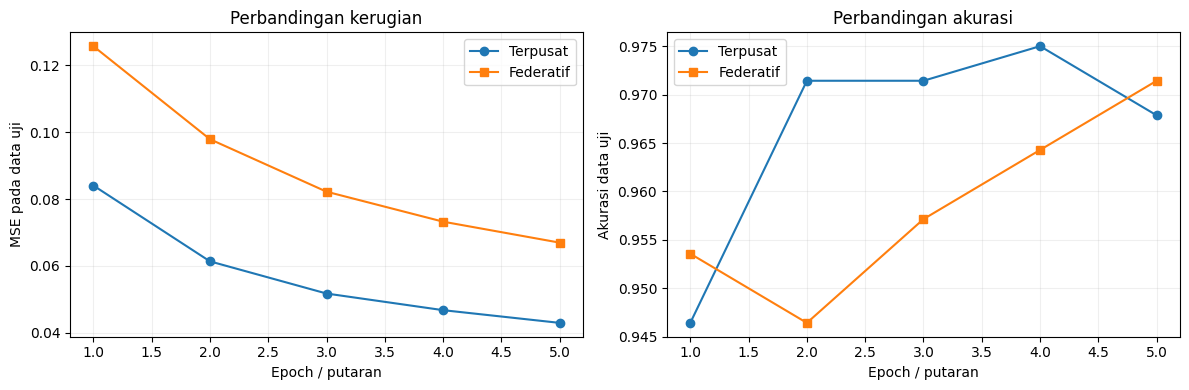

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
periode = np.arange(1, 6)
axes[0].plot(periode, histori_terpusat["rugi_uji"], marker="o", label="Terpusat")
axes[0].plot(periode, histori_federatif["rugi_uji"], marker="s", label="Federatif")
axes[0].set(xlabel="Epoch / putaran", ylabel="MSE pada data uji", title="Perbandingan kerugian")
axes[0].legend()
axes[0].grid(alpha=0.2)
axes[1].plot(periode, histori_terpusat["akurasi_uji"], marker="o", label="Terpusat")
axes[1].plot(periode, histori_federatif["akurasi_uji"], marker="s", label="Federatif")
axes[1].set(xlabel="Epoch / putaran", ylabel="Akurasi data uji", title="Perbandingan akurasi")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Analisis:** Kedua pendekatan mempelajari tugas yang sama, tetapi laju dan lintasan pelatihannya boleh berbeda. Satu epoch server pusat tidak identik secara matematis dengan satu putaran FedAvg (karena model lokal dikerjakan terpisah sebelum dirata-ratakan). Jika klien mempunyai distribusi data berbeda (*non-IID*) atau ada klien yang tidak terhubung, kualitas dan kestabilan FedAvg dapat menurun.

## 7. Demonstrasi risiko kebocoran melalui pembaruan bobot

Buku memakai sebuah contoh email fiktif untuk menunjukkan bahwa sebuah model *embedding* dengan pembaruan yang jarang (*sparse*) dapat mengungkap kata-kata yang muncul dalam contoh latihan. Berikut kita lakukan eksperimen **hanya dengan kalimat buatan**, bukan dengan email pribadi.

Jika model sebelumnya bernilai nol, bobot kata yang tidak muncul dalam email tidak berubah. Pihak yang memperoleh kedua versi model dapat membandingkannya dan menyusun dugaan tentang kata yang muncul. Ini contoh **kebocoran kata**, bukan pembuktian bahwa isi atau urutan seluruh email pasti dapat direkonstruksi.

In [10]:
kalimat_rekaan = "catatan sandi latihan adalah mangga"
kata_demo = kalimat_rekaan.split()
kamus_demo = sorted(set(kata_demo + ["rapat", "kelas", "laporan", "kantor", "pesan"]))
peta_demo = {kata: i for i, kata in enumerate(kamus_demo)}
email_demo = np.array([peta_demo[k] for k in kata_demo], dtype=int)
sebelum = ModelEmail(len(kamus_demo))
sesudah = sebelum.salin()
_ = sesudah.langkah_latih([email_demo], np.array([0]), laju_belajar=0.8)
perbedaan = sesudah.bobot - sebelum.bobot
terdeteksi = [kamus_demo[i] for i in np.where(np.abs(perbedaan) > 1e-12)[0]]
print("Kata yang dapat diinferensi dari perubahan bobot:", terdeteksi)
print("Jumlah kata terungkap:", len(terdeteksi), "dari", len(kata_demo))
assert set(terdeteksi) == set(kata_demo)

Kata yang dapat diinferensi dari perubahan bobot: ['adalah', 'catatan', 'latihan', 'mangga', 'sandi']
Jumlah kata terungkap: 5 dari 5


**Mengapa ini penting?** Pengiriman gradien/parameter secara langsung dapat membocorkan informasi, walaupun email aslinya tidak dikirim. Eksperimen di atas sangat sederhana; model modern memiliki risiko dan teknik serangan berbeda. Pembaruan yang berasal dari banyak contoh umumnya lebih sulit untuk dianalisis per contoh, tetapi tidak otomatis aman.

## 8. *Randomized response*: intuisi privasi statistik

Buku memakai analogi survei privat: peserta melempar koin pertama; bila hasilnya sisi tertentu, ia menjawab jujur, sedangkan bila tidak, jawabannya ditentukan koin kedua. Orang yang melihat satu jawaban tidak dapat memastikan apakah jawabannya sungguhan atau hasil acak.

Dengan kedua koin seimbang, peluang jawaban “ya” teramati adalah

\[
P(Y_{\mathrm{lapor}}=1)=\tfrac12p_{\mathrm{sebenarnya}}+\tfrac14,
\qquad \widehat p=2(P(Y_{\mathrm{lapor}}=1)-\tfrac14).
\]

Teknik ini memberikan ilustrasi privasi statistik. **Randomized response bukan secure aggregation**, dan klaim *differential privacy* formal memerlukan definisi ancaman, pengaturan acak, serta pembuktian dan perhitungan parameter privasi yang sesuai.

Proporsi sebenarnya (hanya peneliti simulasi yang tahu): 0.387
Proporsi 'ya' yang dilaporkan: 0.446
Estimasi dari randomized response: 0.392


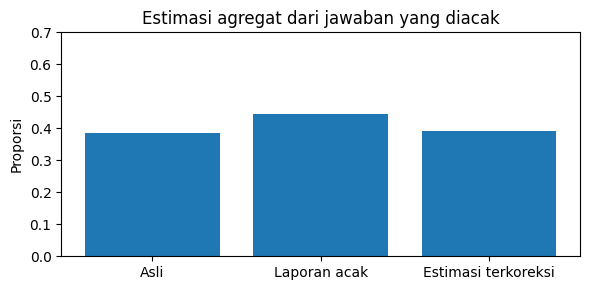

In [11]:
n_responden = 10000
jawaban_asli = rng.random(n_responden) < 0.38
koin_pertama = rng.random(n_responden) < 0.5
koin_kedua = rng.random(n_responden) < 0.5
jawaban_dilaporkan = np.where(koin_pertama, jawaban_asli, koin_kedua)
proporsi_asli = jawaban_asli.mean()
proporsi_lapor = jawaban_dilaporkan.mean()
estimasi = np.clip(2 * (proporsi_lapor - 0.25), 0, 1)
print(f"Proporsi sebenarnya (hanya peneliti simulasi yang tahu): {proporsi_asli:.3f}")
print(f"Proporsi 'ya' yang dilaporkan: {proporsi_lapor:.3f}")
print(f"Estimasi dari randomized response: {estimasi:.3f}")
assert abs(estimasi - proporsi_asli) < 0.08
plt.figure(figsize=(6, 3))
plt.bar(["Asli", "Laporan acak", "Estimasi terkoreksi"],
        [proporsi_asli, proporsi_lapor, estimasi])
plt.ylim(0, 0.7)
plt.ylabel("Proporsi")
plt.title("Estimasi agregat dari jawaban yang diacak")
plt.tight_layout()
plt.show()

## 9. Penggabungan aman (*secure aggregation*)

Tujuan penggabungan aman adalah agar penggabung dapat mengetahui **jumlah pembaruan** tanpa melihat masing-masing pembaruan. Secara konseptual, jika klien menyimpan rahasia pembaruan \(u_1,u_2,u_3\), server hanya boleh menerima \(u_1+u_2+u_3\).

Salah satu ilustrasi non-kriptografis adalah **masking yang saling menghapus**:

\[
\begin{aligned}
\widetilde u_1 &= u_1+r_{12}+r_{13},\\
\widetilde u_2 &= u_2-r_{12}+r_{23},\\
\widetilde u_3 &= u_3-r_{13}-r_{23}.
\end{aligned}
\]

Ketika tiga pesan dijumlah, semua mask hilang sehingga didapat jumlah yang benar. Contoh NumPy berikut **belum** menjadi protokol secure aggregation siap produksi karena belum menangani kolusi, pembagian kunci, pembatalan partisipasi, dan autentikasi.

In [12]:
update_asli = np.array([[0.3, -0.1, 0.2],
                         [-0.2, 0.4, 0.1],
                         [0.1, -0.05, 0.3]])
r12, r13, r23 = [rng.normal(size=3) for _ in range(3)]
update_bermasker = np.vstack([
    update_asli[0] + r12 + r13,
    update_asli[1] - r12 + r23,
    update_asli[2] - r13 - r23
])
print("Jumlah pembaruan asli:    ", update_asli.sum(axis=0))
print("Jumlah pembaruan bermasker:", update_bermasker.sum(axis=0))
assert np.allclose(update_asli.sum(axis=0), update_bermasker.sum(axis=0))

Jumlah pembaruan asli:     [0.2  0.25 0.6 ]
Jumlah pembaruan bermasker: [0.2  0.25 0.6 ]


## 10. Enkripsi homomorfik: menjumlahkan nilai terenkripsi

Enkripsi homomorfik adalah keluarga teknik yang memungkinkan operasi tertentu dilakukan pada data dalam keadaan terenkripsi. Bab 15 memperkenalkan **Paillier**, yang mendukung penjumlahan terenkripsi.

- **Kunci publik:** dipakai peserta untuk mengenkripsi.
- **Kunci privat:** dipakai pemegang kunci untuk mendekripsi.
- **Plaintext:** bilangan sebelum enkripsi; **ciphertext:** hasil enkripsi.
- Untuk enkripsi aditif: \(D(E(a)\oplus E(b))=a+b\).

Agar notebook **tetap dapat dijalankan offline**, kami menyediakan demonstrasi Paillier kecil berbasis pustaka standar Python. Apabila pustaka `phe` tersedia, bagian ini memakainya sesuai ide buku. Jika unduhan dataset berhasil namun `phe` belum terpasang, notebook mencoba memasangnya otomatis. **Implementasi bawaan hanya untuk pendidikan, dengan kunci sangat kecil dan tidak aman untuk data nyata.**

In [13]:
# Lapisan antarmuka untuk operasi enkripsi (library phe jika tersedia,
# atau Paillier kecil yang benar secara matematika tetapi TIDAK aman).
try:
    import phe
    PHE_TERSEDIA = True
except ImportError:
    PHE_TERSEDIA = False
    if STATUS_DATA.startswith("DATA ASLI"):
        # Pengambilan data sukses: koneksi mungkin tersedia di Google Colab.
        # Jika pemasangan gagal, demonstrasi tetap berjalan dengan Paillier mini.
        try:
            import subprocess
            subprocess.run([sys.executable, "-m", "pip", "-q", "install", "phe"],
                           timeout=35, check=True, capture_output=True)
            import phe
            PHE_TERSEDIA = True
            print("Pustaka phe berhasil dipasang.")
        except Exception as err:
            print("phe tidak tersedia; gunakan demonstrasi offline:", type(err).__name__)

class PaillierBelajar:
    """Demonstrasi matematis Paillier, bukan perangkat kriptografi produksi."""
    def __init__(self):
        # Dua prima kecil tetap agar eksperimen dapat direproduksi.
        p, q = 1000003, 1000033
        self.n = p * q
        self.n2 = self.n ** 2
        self.g = self.n + 1
        lam = math.lcm(p - 1, q - 1)
        self.mu = pow(lam, -1, self.n)
        self.skala = 10**6

    def enkripsi(self, angka):
        pesan = int(round(float(angka) * self.skala))
        if abs(pesan) >= self.n // 8:
            raise ValueError("Angka terlalu besar untuk contoh Paillier.")
        r = secrets.randbelow(self.n - 1) + 1
        while math.gcd(r, self.n) != 1:
            r = secrets.randbelow(self.n - 1) + 1
        c = (pow(self.g, pesan % self.n, self.n2) * pow(r, self.n, self.n2)) % self.n2
        return TeksSandiBelajar(c, self)

    def dekripsi(self, sandi):
        u = pow(sandi.nilai, math.lcm(1000002, 1000032), self.n2)
        l = (u - 1) // self.n
        pesan = (l * self.mu) % self.n
        if pesan > self.n // 2:
            pesan -= self.n
        return pesan / self.skala

class TeksSandiBelajar:
    def __init__(self, nilai, kunci):
        self.nilai, self.kunci = nilai, kunci
    def __add__(self, lain):
        if self.kunci is not lain.kunci:
            raise ValueError("Penjumlahan memerlukan kunci yang sama")
        return TeksSandiBelajar((self.nilai * lain.nilai) % self.kunci.n2, self.kunci)

if PHE_TERSEDIA:
    kunci_publik, kunci_privat = phe.generate_paillier_keypair(n_length=1024)
    def enkripsi(angka): return kunci_publik.encrypt(float(angka))
    def dekripsi(sandi): return float(kunci_privat.decrypt(sandi))
    JENIS_ENKRIPSI = "Paillier melalui pustaka phe (1024 bit hanya demonstrasi)"
else:
    kunci_belajar = PaillierBelajar()
    def enkripsi(angka): return kunci_belajar.enkripsi(angka)
    def dekripsi(sandi): return kunci_belajar.dekripsi(sandi)
    JENIS_ENKRIPSI = "Paillier mini untuk pendidikan (TIDAK AMAN)"

print("Metode:", JENIS_ENKRIPSI)
a_terenkripsi = enkripsi(5)
b_terenkripsi = enkripsi(3)
hasil_terenkripsi = a_terenkripsi + b_terenkripsi
hasil_terbuka = dekripsi(hasil_terenkripsi)
print("Dekripsi(E(5) + E(3)) =", hasil_terbuka)
assert abs(hasil_terbuka - 8) < 1e-5

Pustaka phe berhasil dipasang.
Metode: Paillier melalui pustaka phe (1024 bit hanya demonstrasi)
Dekripsi(E(5) + E(3)) = 8.0


**Catatan keamanan:** Angka 1024 bit di contoh buku mencerminkan konteks pendidikan pada saat buku terbit. Penggunaan sistem modern memerlukan pemilihan parameter, pustaka, protokol ancaman, dan audit keamanan yang sesuai. Jangan gunakan Paillier mini atau contoh notebook ini untuk menyimpan data pribadi.

## 11. Federated Learning dengan penggabungan terenkripsi

Buku menggabungkan model terenkripsi dari Bob, Alice, dan Sue. Untuk menjalankan contoh lengkap tanpa mengenkripsi ribuan bobot (yang lambat), kita memakai **subset 32 kata dari data latihan yang sama**. Proses penggabungan tetap berlaku pada **setiap bobot dari model subset**, bukan hanya satu angka ilustratif.

Protokol demo:

1. Penggabung mengirim bobot global dan kunci publik ke setiap klien.
2. Klien melatih model pada email lokal.
3. Klien mengenkripsi **pembaruan bobot yang telah dikalikan fraksi jumlah contoh**.
4. Pembaruan terenkripsi dijumlahkan.
5. Hanya **hasil penjumlahan terenkripsi** didekripsi, lalu ditambahkan ke bobot global.

**Perbaikan penting dari cuplikan halaman 290 pada buku:** yang didekripsi wajib `hasil_agregasi_terenkripsi`, bukan salah satu bobot terenkripsi individual (kesalahan penamaan variabel pada cuplikan tersebut).

Perlu dipahami: contoh ini tidak menyelenggarakan protokol aman multi-pihak yang lengkap. Bila pihak pemegang kunci privat memperoleh ciphertext tiap klien, ia masih dapat mendekripsinya. Sebuah sistem nyata harus membatasi apa yang boleh diterima atau didekripsi oleh penggabung, termasuk memperhitungkan kolusi dan batas minimum peserta.

In [14]:
UKURAN_KAMUS_KRIPTO = min(32, len(kamus))
kamus_kecil = kamus[:UKURAN_KAMUS_KRIPTO]
peta_kecil = {kata: i for i, kata in enumerate(kamus_kecil)}
x_kecil = [indeks_email(teks, peta_kecil) for teks, _ in latih_raw]
x_uji_kecil = [indeks_email(teks, peta_kecil) for teks, _ in uji_raw]
klien_kecil = bagi_ke_klien(x_kecil, y_latih)
model_kripto = ModelEmail(UKURAN_KAMUS_KRIPTO)
model_kripto_tanpa_enkripsi = ModelEmail(UKURAN_KAMUS_KRIPTO)

# Uji identitas aljabar: hasil penjumlahan pembaruan terenkripsi
# harus merekonstruksi jumlah plaintext hingga galat pembulatan.
uji_pembaruan = [np.array([0.12, -0.07]), np.array([-0.02, 0.10]), np.array([0.11, -0.04])]
hasil_sandi = [enkripsi(0.0), enkripsi(0.0)]
for nilai_k in uji_pembaruan:
    hasil_sandi = [a + enkripsi(b) for a, b in zip(hasil_sandi, nilai_k)]
hasil_buka = np.array([dekripsi(z) for z in hasil_sandi])
print("Penjumlahan biasa:    ", np.sum(uji_pembaruan, axis=0))
print("Penjumlahan terenkripsi:", hasil_buka)
assert np.allclose(hasil_buka, np.sum(uji_pembaruan, axis=0), atol=1e-5)

Penjumlahan biasa:     [ 0.21 -0.01]
Penjumlahan terenkripsi: [ 0.21 -0.01]


### 11.1. Pelatihan model kecil dan penggabungan ciphertext

In [15]:
def satu_putaran_terenkripsi(model_global, pembagian, laju=0.5, epoch_lokal=1):
    n_total = sum(len(yk) for _, yk in pembagian.values())
    agregat_sandi = [enkripsi(0.0) for _ in range(len(model_global.bobot))]
    # Tiap klien hanya menghasilkan delta-nya, lalu mengenkripsi kontribusi tertimbang.
    for nama, (xk, yk) in pembagian.items():
        lokal, _ = jalankan_lokal(model_global, xk, yk,
                                 epoch=epoch_lokal, ukuran_batch=64, alpha=laju)
        delta_tertimbang = (lokal.bobot - model_global.bobot) * (len(yk) / n_total)
        ciphertext_klien = [enkripsi(angka) for angka in delta_tertimbang]
        agregat_sandi = [jumlah + kontribusi for jumlah, kontribusi
                         in zip(agregat_sandi, ciphertext_klien)]
    # Penting: hanya jumlah dari semua klien yang didekripsi.
    delta_total = np.array([dekripsi(angka) for angka in agregat_sandi])
    hasil = model_global.salin()
    hasil.bobot = hasil.bobot + delta_total
    return hasil

# Untuk membandingkan pembaruan secara adil: gunakan urutan data yang sama
# dengan menyimpan dan memulihkan status generator NumPy sebelum tiap putaran.
import copy
histori_kripto = []
for putaran in range(2):
    keadaan = copy.deepcopy(rng.bit_generator.state)
    model_kripto_tanpa_enkripsi, _ = satu_putaran_federatif(
        model_kripto_tanpa_enkripsi, klien_kecil, alpha=0.5)
    rng.bit_generator.state = copy.deepcopy(keadaan)
    model_kripto = satu_putaran_terenkripsi(model_kripto, klien_kecil, laju=0.5)
    selisih = np.max(np.abs(model_kripto.bobot - model_kripto_tanpa_enkripsi.bobot))
    angka_metrik = metrik(model_kripto, x_uji_kecil, y_uji)
    histori_kripto.append(angka_metrik["akurasi"])
    print(f"Putaran {putaran+1}: akurasi uji subset={angka_metrik['akurasi']:.2%}; "
          f"selisih terhadap agregasi biasa={selisih:.8f}")
    assert selisih < 5e-5

print("Perbandingan enkripsi dan tanpa enkripsi konsisten (dalam toleransi pembulatan).")
print("STATUS DATA:", STATUS_DATA)

Putaran 1: akurasi uji subset=68.57%; selisih terhadap agregasi biasa=0.00000000
Putaran 2: akurasi uji subset=77.86%; selisih terhadap agregasi biasa=0.00000000
Perbandingan enkripsi dan tanpa enkripsi konsisten (dalam toleransi pembulatan).
STATUS DATA: DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku


### 11.2. Pembahasan hasil

- Akurasi model 32 kata tidak boleh dibandingkan secara langsung dengan model yang memakai ribuan kata: fitur yang tersedia berbeda.
- Jika agregasi terenkripsi benar, bobot yang diperoleh harus **mendekati** bobot hasil agregasi biasa. Perbedaan kecil berasal dari pengkodean angka pecahan ke dalam skema enkripsi.
- Enkripsi tidak menambah informasi yang dipelajari. Tujuannya adalah **membatasi akses ke pembaruan individual** dalam protokol yang dirancang dengan baik.
- Simulasi ini belum membuktikan privasi formal: privasi bergantung pada protokol, jumlah peserta, pemegang kunci, perlindungan kanal komunikasi, dan kemungkinan kolusi.

## 12. Perbandingan ketiga skenario

In [16]:
m_pusat = metrik(model_terpusat, x_uji, y_uji)
m_federasi = metrik(model_federatif, x_uji, y_uji)
m_aman = metrik(model_kripto, x_uji_kecil, y_uji)
print("HASIL AKHIR (", STATUS_DATA, ")")
print("-" * 60)
for judul, hasil, penjelas in [
    ("Terpusat", m_pusat, "kamus penuh"),
    ("Federatif tanpa enkripsi", m_federasi, "kamus penuh"),
    ("Federatif dengan enkripsi", m_aman, "kamus subset")]:
    print(f"{judul:28s} | akurasi {hasil['akurasi']:.2%} | "
          f"F1 {hasil['f1']:.3f} | MSE {hasil['mse']:.4f} | {penjelas}")
print("CATATAN: skenario enkripsi memakai fitur lebih sedikit; jangan diartikan sebagai uji keunggulan akurasi.")

HASIL AKHIR ( DATA ASLI: berkas spam.txt dan ham.txt dari repositori buku )
------------------------------------------------------------
Terpusat                     | akurasi 96.79% | F1 0.969 | MSE 0.0429 | kamus penuh
Federatif tanpa enkripsi     | akurasi 97.14% | F1 0.972 | MSE 0.0669 | kamus penuh
Federatif dengan enkripsi    | akurasi 77.86% | F1 0.762 | MSE 0.2085 | kamus subset
CATATAN: skenario enkripsi memakai fitur lebih sedikit; jangan diartikan sebagai uji keunggulan akurasi.
